# Лабораторная работа №1. Регрессионный анализ

**Студент:** Александров Артемий Владимирович  
**Вариант:** 5  
**Данные:** `lab1-05.csv`

## 1. Загрузка данных

In [106]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression #класс прямой и полиномиальной регрессии для подбора кэфов
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score #MSE MAE R2
from sklearn.model_selection import train_test_split #делит строки на обучение и проверку
from sklearn.pipeline import Pipeline #контейнер, который склеивает два шага в один: сначала степени x, потом регрессия
from sklearn.preprocessing import PolynomialFeatures #преобразователь, который из столбца x делает столбцы x, x2, x3

data = pd.read_csv("lab1-05.csv", header=None, names=["x", "y"])
print(f"Наблюдений: {len(data)}")
data.head(10)

Наблюдений: 200


,x,y
0,8.313131,1.958272
1,4.878788,0.690539
2,2.898990,5.182053
3,7.303030,-0.801916
4,8.757576,2.016715
5,8.151515,1.844808
6,1.121212,17.472711
7,1.808081,11.093722
8,8.030303,0.582904
9,6.858586,0.599809


## 2. Визуализация исходных данных

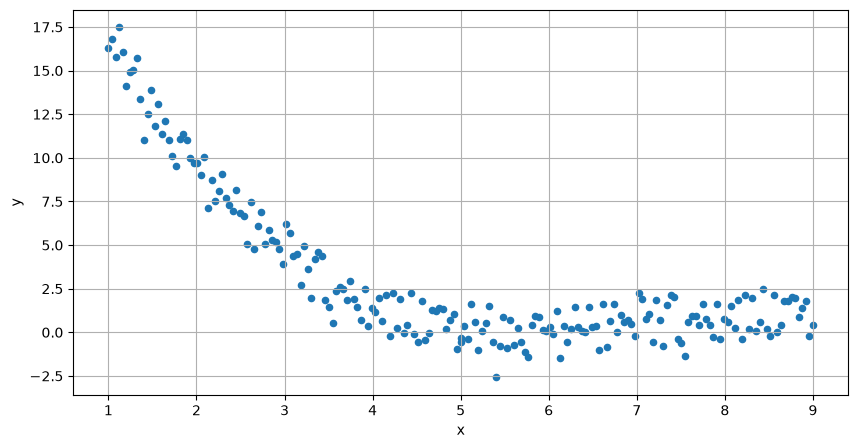

In [107]:
plt.figure(figsize=(10,5))
plt.scatter(data["x"], data["y"], s=20)
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.show()

## 3. Разбиение на обучающую и тестовую выборки


In [108]:
X = data[["x"]]
y = data["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Обучающая выборка: {len(X_train)}")
print(f"Тестовая выборка: {len(X_test)}")

Обучающая выборка: 160
Тестовая выборка: 40


## 4. Выбор и обучение модели



In [109]:
def metrics_row(title, model):
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    return {
        "Модель": title,
        "MSE, обучение": mean_squared_error(y_train, pred_train),
        "MAE, обучение": mean_absolute_error(y_train, pred_train),
        "R2, обучение": r2_score(y_train, pred_train),
        "MSE, тест": mean_squared_error(y_test, pred_test),
        "MAE, тест": mean_absolute_error(y_test, pred_test),
        "R2, тест": r2_score(y_test, pred_test),
    }


candidates = {}
for degree in range(1, 6):
    candidate = Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("lin", LinearRegression()),
    ])
    candidate.fit(X_train, y_train)
    candidates[degree] = candidate

comparison = pd.DataFrame([
    metrics_row(f"полином степени {degree}", candidates[degree])
    for degree in candidates
])
comparison.round(4)

,Модель,"MSE, обучение","MAE, обучение","R2, обучение","MSE, тест","MAE, тест","R2, тест"
0,полином степени 1,8.3916,2.4010,0.5633,8.5698,2.3326,0.6334
1,полином степени 2,1.4910,1.0136,0.9224,1.5356,1.0006,0.9343
2,полином степени 3,0.8064,0.7568,0.9580,1.1160,0.8142,0.9523
3,полином степени 4,0.8007,0.7498,0.9583,1.1187,0.8308,0.9521
4,полином степени 5,0.7988,0.7457,0.9584,1.1155,0.8296,0.9523


## 5. Анализ качества выбранной модели

In [110]:
linear_model = candidates[1]
model = candidates[3]

quality = pd.DataFrame([
    metrics_row("прямая", linear_model),
    metrics_row("полином 3-й степени", model),
])
quality.round(4)

,Модель,"MSE, обучение","MAE, обучение","R2, обучение","MSE, тест","MAE, тест","R2, тест"
0,прямая,8.3916,2.4010,0.5633,8.5698,2.3326,0.6334
1,полином 3-й степени,0.8064,0.7568,0.9580,1.1160,0.8142,0.9523


In [111]:
def format_formula(regression):
    terms = [f"{regression.intercept_:.4f}"]
    for power, coef in enumerate(regression.coef_, start=1):
        sign = "+" if coef >= 0 else "-"
        variable = "x" if power == 1 else f"x^{power}"
        terms.append(f"{sign} {abs(coef):.4f} {variable}")
    return "y = " + " ".join(terms)


linear_formula = format_formula(linear_model.named_steps["lin"])
formula = format_formula(model.named_steps["lin"])

print("Прямая:")
print(linear_formula)
print()
print("Эмпирическая формула:")
print(formula)

Прямая:
y = 10.3382 - 1.4521 x

Эмпирическая формула:
y = 28.1785 - 12.6156 x + 1.8369 x^2 - 0.0858 x^3


## 6. Визуализация результата

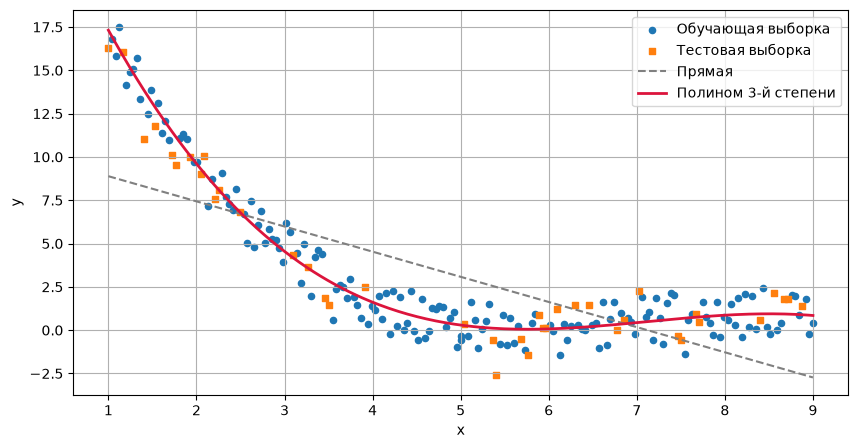

In [112]:
x_grid = np.linspace(data["x"].min(), data["x"].max(), 300)
grid = pd.DataFrame({"x": x_grid})

plt.figure(figsize=(10, 5))
plt.scatter(X_train["x"], y_train, s=20, label="Обучающая выборка")
plt.scatter(X_test["x"], y_test, s=20, marker="s", label="Тестовая выборка")
plt.plot(grid["x"], linear_model.predict(grid), color="gray", linestyle="--", label="Прямая")
plt.plot(grid["x"], model.predict(grid), color="crimson", linewidth=2, label="Полином 3-й степени")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

## Вывод

Прямая `y = 10.3382 - 1.4521 x` передаёт только общий наклон. На тестовых 40 точках у неё MSE = 8.57 и R² = 0.63.

Полином 3 степени на тесте MSE = 1.12, MAE =0.81, R² = 0.95. Степени 4 и 5 эту ошибку уже не уменьшают, поэтому итоговая эмпирическая формула:

`y = 28.1785 - 12.6156 x + 1.8369 x^2 - 0.0858 x^3`

Коэффициенты посчитаны по 160 обучающим точкам.